In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import (fijar_semilla, dispositivo, contar_parametros, entrenar, predecir,
                                   guardar_modelo, guardar_resultados)
from energia.metricas import evaluar, error_por_hora, naive_estacional, tabla
from energia.modelos import transformer
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
NOMBRE = "transformer"
fijar_semilla()
print("torch", torch.__version__, "| dispositivo:", dispositivo())

torch 2.5.1+cpu | dispositivo: cpu


In [2]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [3]:
HP_MODELO = {"d_model": 64, "nhead": 4, "capas_codificador": 2, "capas_decodificador": 1,
             "dim_ff": 128, "dropout": 0.2, "corregir_naive": True}
HP_ENTRENAMIENTO = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

modelo = transformer.construir(datos, **HP_MODELO)
print(modelo)
print("parámetros entrenables:", contar_parametros(modelo))

TransformerPronostico(
  (entrada_pasado): Linear(in_features=16, out_features=64, bias=True)
  (entrada_futuro): Linear(in_features=9, out_features=64, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (codificador): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
    (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (decodificador): Transf

In [4]:
historial = entrenar(modelo, datos, **HP_ENTRENAMIENTO)

época   1 | train 0.2073 | val 0.2035 | 110.8 s *


época   2 | train 0.1188 | val 0.1995 | 113.7 s *


época   3 | train 0.0991 | val 0.2006 | 112.9 s


época   4 | train 0.0917 | val 0.1876 | 111.7 s *


época   5 | train 0.0858 | val 0.1992 | 112.1 s


...

época   8 | train 0.0720 | val 0.2291 | 112.8 s


época   9 | train 0.0686 | val 0.2331 | 113.0 s


época  10 | train 0.0653 | val 0.2418 | 112.5 s


época  11 | train 0.0625 | val 0.2497 | 113.1 s


época  12 | train 0.0603 | val 0.2369 | 112.9 s
Early stopping: 8 épocas sin mejorar en validación.


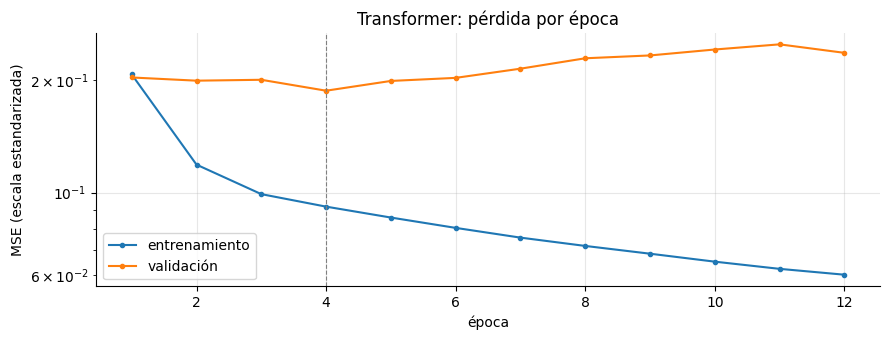

,train,val,segundos
epoca,,,
4,0.091722,0.187553,111.739496


In [5]:
fig = curvas_aprendizaje(historial, "Transformer: pérdida por época")
guardar_figura(fig, "f2_05_transformer_curvas")
plt.show()
historial.loc[[historial["val"].idxmin()]]

In [6]:
resultados = {}
predicciones = {}
for split in ["val", "test"]:
    y = datos.y_original(split)
    predicciones[split] = predecir(modelo, datos, split)
    resultados[("transformer", split)] = evaluar(y, predicciones[split])
    resultados[("naive_m24", split)] = evaluar(y, naive_estacional(datos, split, m=24))
    resultados[("naive_m168", split)] = evaluar(y, naive_estacional(datos, split, m=168))

metricas = tabla(resultados)
metricas.index = pd.MultiIndex.from_tuples(metricas.index, names=["modelo", "split"])
metricas.sort_index()

demanda_MAE  precio_MAE   demanda_RMSE  precio_RMSE  \
modelo      split                                                          
naive_m168  test   121128.936093  126.488172  201826.283211   182.248794   
            val    111762.365881   81.734684  179377.523882   136.076668   
naive_m24   test   194816.646206   56.109531  273062.870794   111.123112   
            val    194135.892010   48.523627  274407.867423   111.794765   
transformer test    85084.542818   59.613179  115871.576969   108.046322   
            val     81210.524105   50.789295  119342.272251   111.485063   

                   demanda_MAPE_%  precio_MAPE_%  demanda_R2  precio_R2  
modelo      split                                                        
naive_m168  test         4.059732      34.665457    0.491508   0.680121  
            val          3.833292      37.448509    0.540316   0.223636  
naive_m24   test         6.670997      14.863168    0.069204   0.881077  
            val          6.718642      20.336838   -0.075762   0.475988  
transformer test         2.824565      14.969571    0.832397   0.887572  
            val          2.774645      22.212343    0.796525   0.478887

In [7]:
metricas.loc[(slice(None), "val"), ["demanda_MAPE_%", "precio_MAPE_%", "demanda_MAE", "precio_MAE"]]

,,demanda_MAPE_%,precio_MAPE_%,demanda_MAE,precio_MAE
modelo,split,,,,
transformer,val,2.774645,22.212343,81210.524105,50.789295
naive_m24,val,6.718642,20.336838,194135.892010,48.523627
naive_m168,val,3.833292,37.448509,111762.365881,81.734684


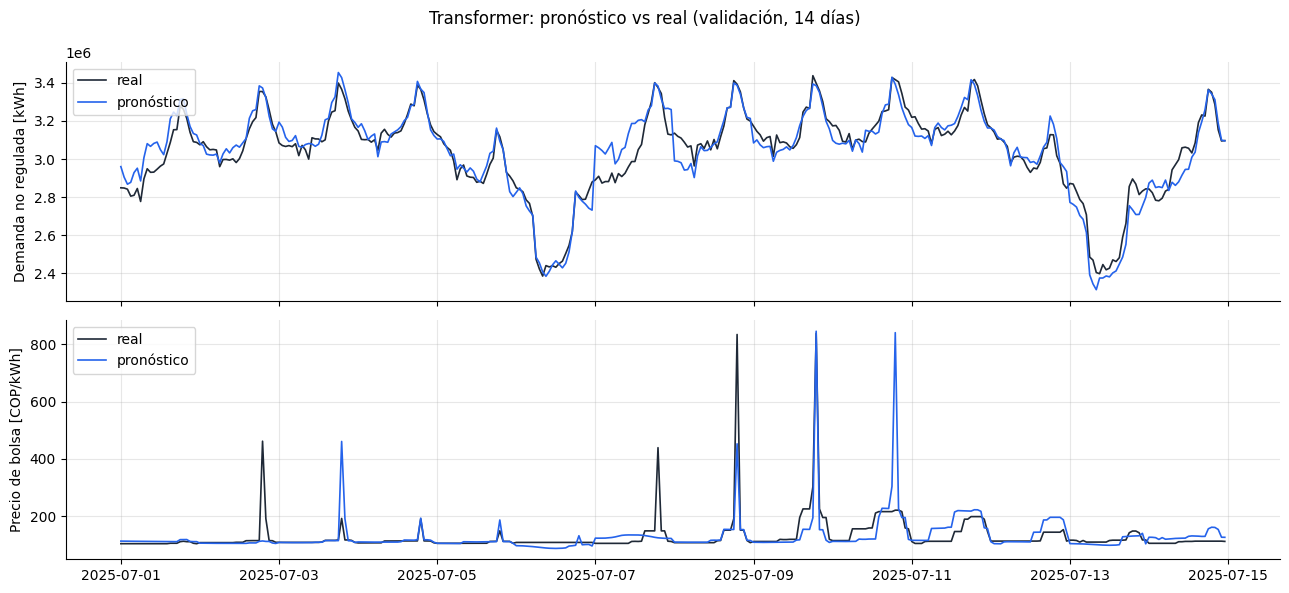

In [8]:
fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="Transformer: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f2_05_transformer_pronostico_val")
plt.show()

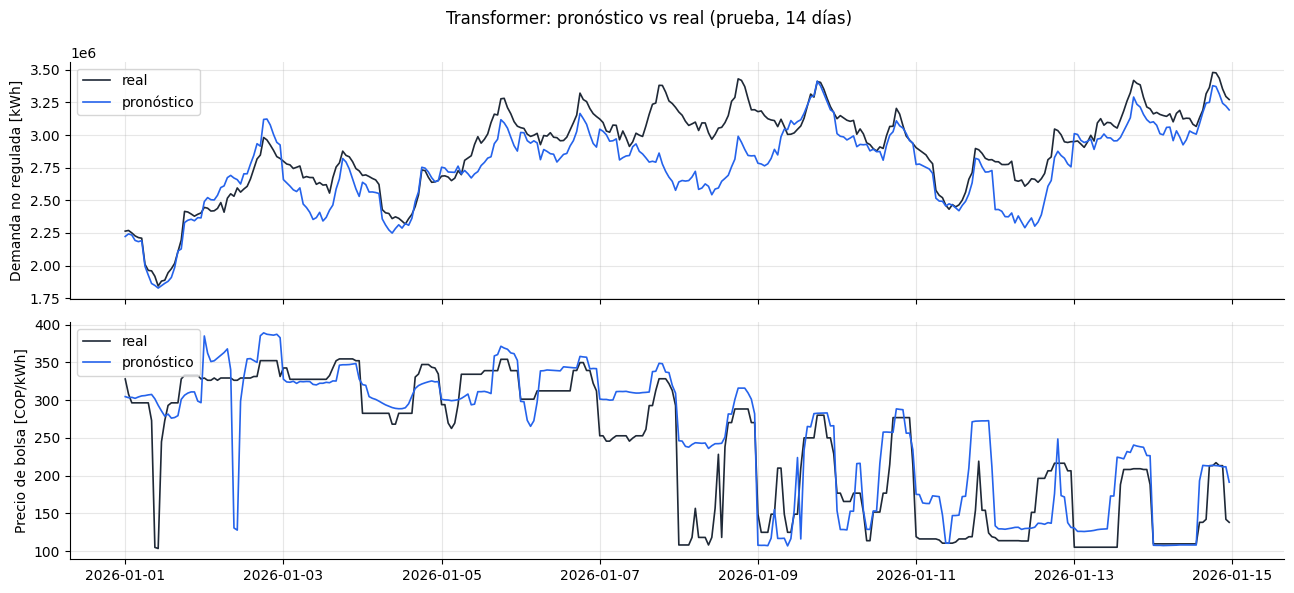

In [9]:
fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="Transformer: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f2_05_transformer_pronostico_test")
plt.show()

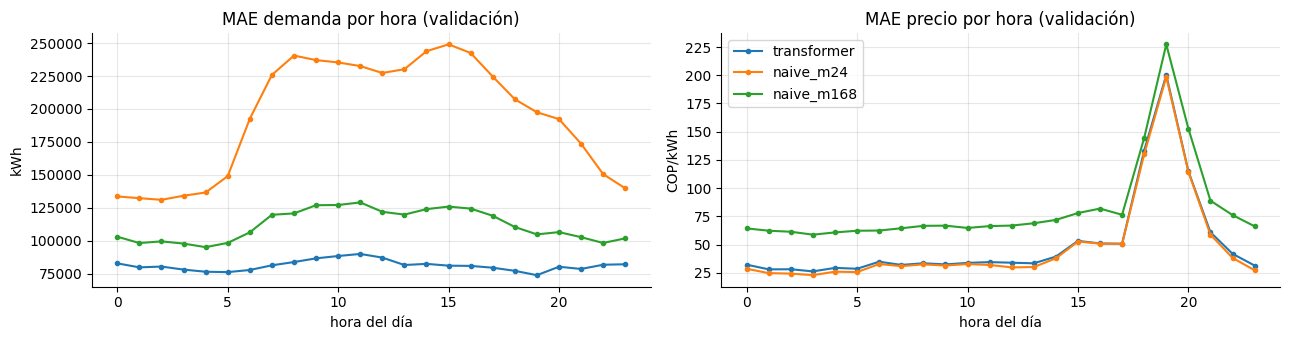

In [10]:
y_val = datos.y_original("val")
errores = {
    "transformer": error_por_hora(y_val, predicciones["val"]),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f2_05_transformer_error_por_hora")
plt.show()

In [11]:
hiperparametros = {**HP_MODELO, **HP_ENTRENAMIENTO, "parametros": contar_parametros(modelo),
                   "mejor_epoca": int(historial["val"].idxmin()), "epocas_entrenadas": len(historial)}
print(guardar_modelo(modelo, NOMBRE, hiperparametros))
print(guardar_resultados(NOMBRE, metricas, hiperparametros, historial))

C:\Users\Usuario\Documents\GitHub\pronostico-energia-nr\results\modelos\transformer.pt
C:\Users\Usuario\Documents\GitHub\pronostico-energia-nr\results\fase2\transformer
